# Geometric Distribution

Companion notebook for the [geometric distribution note](../../notes/random_variables_and_distributions/discrete/geometric_distribution.md) and its [exercises](../../exercises/random_variables_and_distributions/geometric_distribution.md).

$X\sim\text{Geometric}(p)$ is the trial number of the first success in independent Bernoulli($p$) trials ($X\in\{1,2,\dots\}$):

$$P(X=k)=(1-p)^{k-1}p,\qquad F(k)=1-(1-p)^k,\qquad E[X]=\frac1p,\qquad \operatorname{Var}(X)=\frac{1-p}{p^2}.$$

Beware that some libraries count the number of *failures* before the first success instead; `scipy.stats.geom` uses the trial-count convention used here.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)  # seeded for reproducible simulations

## Hand-rolled implementation

In [2]:
class GeometricDistribution:
    """Trial number X in {1, 2, ...} of the first success."""

    def __init__(self, p):
        self.p = p

    def pmf(self, k):
        k = np.asarray(k)
        return (1 - self.p) ** (k - 1) * self.p

    def cdf(self, k):
        k = np.asarray(k)
        return 1 - (1 - self.p) ** k

    def mean(self):
        return 1 / self.p

    def var(self):
        return (1 - self.p) / self.p**2

## Check against `scipy.stats`

We compare with `stats.geom` (trial-count convention) and, to illustrate the convention trap, with `stats.nbinom(1, p)` which counts failures $Y=X-1$.

In [3]:
p1, p2 = 0.3, 0.5
k = np.arange(1, 21)
d1, d2 = GeometricDistribution(p1), GeometricDistribution(p2)

pmf1, pmf2 = stats.geom.pmf(k, p1), stats.geom.pmf(k, p2)
cdf1, cdf2 = stats.geom.cdf(k, p1), stats.geom.cdf(k, p2)
print("PMF matches geom:", np.allclose(d1.pmf(k), pmf1), np.allclose(d2.pmf(k), pmf2))
print("CDF matches geom:", np.allclose(d1.cdf(k), cdf1), np.allclose(d2.cdf(k), cdf2))
print("PMF matches nbinom(1, p) at k-1 failures:", np.allclose(d1.pmf(k), stats.nbinom.pmf(k - 1, 1, p1)))

PMF matches geom: True True
CDF matches geom: True True
PMF matches nbinom(1, p) at k-1 failures: True


## Shape of the PMF and CDF

The PMF decreases geometrically from $k=1$; a smaller $p$ gives a longer tail. The CDF rises toward 1 at the rate $(1-p)^k$.

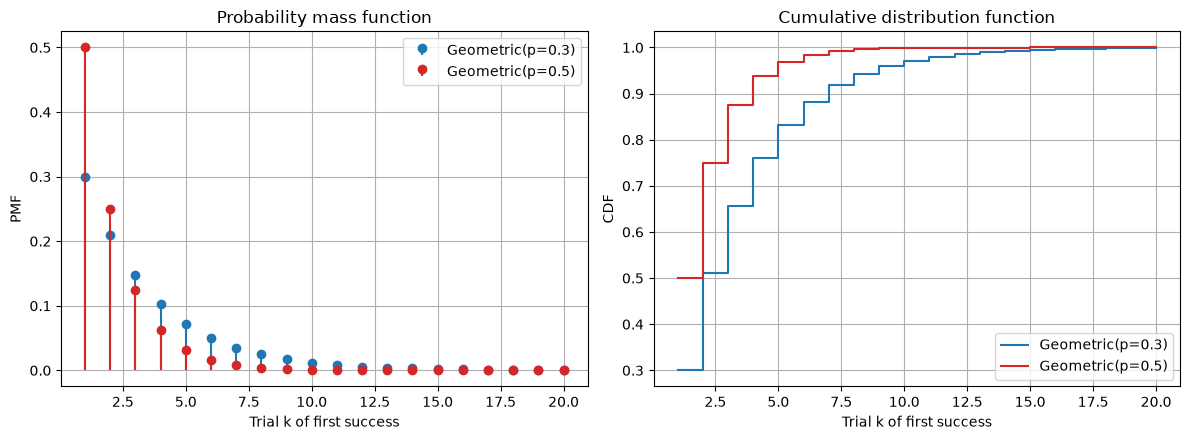

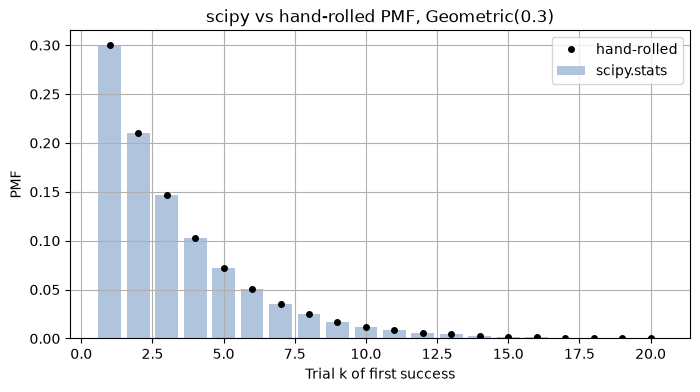

In [4]:
def plot_pmf_cdf(x1, pmf1, cdf1, label1, x2, pmf2, cdf2, label2, xlabel):
    """PMF (stem) and CDF (step) of two distributions side by side."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.stem(x1, pmf1, basefmt=" ", linefmt="C0-", markerfmt="C0o", label=label1)
    ax1.stem(x2, pmf2, basefmt=" ", linefmt="C3-", markerfmt="C3o", label=label2)
    ax1.set(xlabel=xlabel, ylabel="PMF", title="Probability mass function")
    ax2.step(x1, cdf1, where="post", color="C0", label=label1)
    ax2.step(x2, cdf2, where="post", color="C3", label=label2)
    ax2.set(xlabel=xlabel, ylabel="CDF", title="Cumulative distribution function")
    for ax in (ax1, ax2):
        ax.legend()
        ax.grid(True)
    plt.tight_layout()
    plt.show()


def plot_overlay(x, ref, custom, xlabel, title):
    """Hand-rolled values (dots) on top of the scipy.stats values (bars)."""
    plt.figure(figsize=(8, 4))
    plt.bar(x, ref, color="lightsteelblue", label="scipy.stats")
    plt.plot(x, custom, "ko", markersize=4, label="hand-rolled")
    plt.xlabel(xlabel)
    plt.ylabel("PMF")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


plot_pmf_cdf(k, pmf1, cdf1, f"Geometric(p={p1})", k, pmf2, cdf2, f"Geometric(p={p2})", "Trial k of first success")
plot_overlay(k, pmf1, d1.pmf(k), "Trial k of first success", "scipy vs hand-rolled PMF, Geometric(0.3)")

## Worked example: waiting for a 6

Roll a die until a 6 appears ($p=1/6$). This reproduces the numbers in the introduction note, including the memoryless property $P(X>m+n\mid X>m)=P(X>n)$.

In [5]:
die = GeometricDistribution(1 / 6)
print(f"P(X = 3)      = {die.pmf(3):.4f}")
print(f"P(X <= 3)     = {die.cdf(3):.4f}")
print(f"P(X >= 3)     = {1 - die.cdf(2):.4f}")
print(f"E[X], Var(X)  = {die.mean():.1f}, {die.var():.1f}")

# Memorylessness: P(X > 8 | X > 3) equals P(X > 5)
surv = lambda m: 1 - die.cdf(m)
print(f"P(X>8 | X>3) = {surv(8) / surv(3):.5f}   P(X>5) = {surv(5):.5f}")

P(X = 3)      = 0.1157
P(X <= 3)     = 0.4213
P(X >= 3)     = 0.6944
E[X], Var(X)  = 6.0, 30.0
P(X>8 | X>3) = 0.40188   P(X>5) = 0.40188


## Simulation versus theory

`rng.geometric` also returns the trial-count convention. We check the sample mean, variance and the empirical tail probability.

mean: sample 3.344  theory 3.333
var : sample 7.859  theory 7.778
P(X > 5): sample 0.1686  theory 0.1681


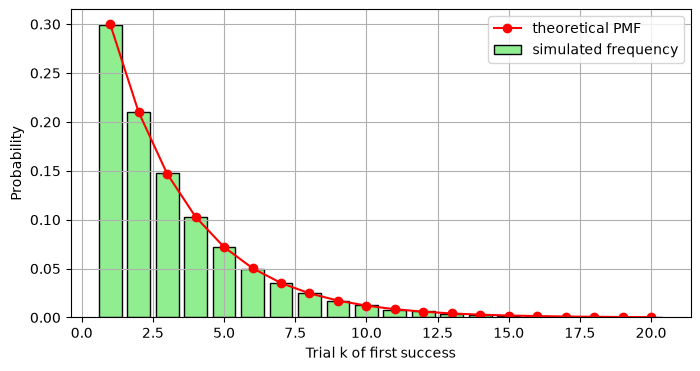

In [6]:
sample = rng.geometric(p1, size=100_000)
print(f"mean: sample {sample.mean():.3f}  theory {d1.mean():.3f}")
print(f"var : sample {sample.var():.3f}  theory {d1.var():.3f}")
print(f"P(X > 5): sample {(sample > 5).mean():.4f}  theory {1 - d1.cdf(5):.4f}")

freq = np.bincount(sample)[1:21] / sample.size
plt.figure(figsize=(8, 4))
plt.bar(k, freq, color="lightgreen", edgecolor="black", label="simulated frequency")
plt.plot(k, d1.pmf(k), "ro-", label="theoretical PMF")
plt.xlabel("Trial k of first success")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

## Takeaways

* The geometric PMF is a geometric sequence; the CDF has the closed form $1-(1-p)^k$.
* It is the only discrete distribution on $\{1,2,\dots\}$ with the memoryless property.
* Check the library convention (trials vs failures) before comparing formulas.